# Project Python Foundations: FoodHub Data Analysis

### Context

The number of restaurants in New York is increasing day by day. Lots of students and busy professionals rely on those restaurants due to their hectic lifestyles. Online food delivery service is a great option for them. It provides them with good food from their favorite restaurants. A food aggregator company FoodHub offers access to multiple restaurants through a single smartphone app.

The app allows the restaurants to receive a direct online order from a customer. The app assigns a delivery person from the company to pick up the order after it is confirmed by the restaurant. The delivery person then uses the map to reach the restaurant and waits for the food package. Once the food package is handed over to the delivery person, he/she confirms the pick-up in the app and travels to the customer's location to deliver the food. The delivery person confirms the drop-off in the app after delivering the food package to the customer. The customer can rate the order in the app. The food aggregator earns money by collecting a fixed margin of the delivery order from the restaurants.

### Objective

The food aggregator company has stored the data of the different orders made by the registered customers in their online portal. They want to analyze the data to get a fair idea about the demand of different restaurants which will help them in enhancing their customer experience. Suppose you are hired as a Data Scientist in this company and the Data Science team has shared some of the key questions that need to be answered. Perform the data analysis to find answers to these questions that will help the company to improve the business.

### Data Description

The data contains the different data related to a food order. The detailed data dictionary is given below.

### Data Dictionary

* order_id: Unique ID of the order
* customer_id: ID of the customer who ordered the food
* restaurant_name: Name of the restaurant
* cuisine_type: Cuisine ordered by the customer
* cost_of_the_order: Cost of the order
* day_of_the_week: Indicates whether the order is placed on a weekday or weekend (The weekday is from Monday to Friday and the weekend is Saturday and Sunday)
* rating: Rating given by the customer out of 5
* food_preparation_time: Time (in minutes) taken by the restaurant to prepare the food. This is calculated by taking the difference between the timestamps of the restaurant's order confirmation and the delivery person's pick-up confirmation.
* delivery_time: Time (in minutes) taken by the delivery person to deliver the food package. This is calculated by taking the difference between the timestamps of the delivery person's pick-up confirmation and drop-off information

### Let us start by importing the required libraries

In [1]:
# Installing the libraries with the specified version.
!pip install numpy==1.25.2 pandas==1.5.3 matplotlib==3.7.1 seaborn==0.13.1 -q --user

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 18.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 19.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 20.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.8/294.8 kB 8.0 MB/s eta 0:00:00
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 1.5.3 which is incompatible.
tensorflow 2.18.0 requires numpy<2.1.0,>=1.26.0, but you have numpy 1.25.2 which is incompatible.
xarray 2025.1.2 requires pandas>=2.1, but you have pandas 1.5.3 which is incompatible.
mizani 0.13.1 requires pandas>=2.2.0, but you have pandas 1.5.3 which is incompatible.
langchain 0.3.19 requires nu

**Note**: *After running the above cell, kindly restart the notebook kernel and run all cells sequentially from the start again.*

In [2]:
# import libraries for data manipulation
import numpy as np
import pandas as pd

# import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

### Understanding the structure of the data

In [3]:
# uncomment and run the following lines for Google Colab
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
# Write your code here to read the data
data = pd.read_csv('/content/drive/MyDrive/PGPAIML-Projects/foodhub_order.csv')

In [6]:
# Write your code here to view the first 5
data.head()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24


### **Question 1:** How many rows and columns are present in the data? [0.5 mark]

In [7]:
# Write your code here
df = data.copy()
df.shape
print("There are", data.shape[0], 'rows and', data.shape[1], "columns.")

There are 1898 rows and 9 columns.


#### Observations:
The dataset has 1898 rows and 9 columns

### **Question 2:** What are the datatypes of the different columns in the dataset? (The info() function can be used) [0.5 mark]

In [8]:
# Write your code here
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               1898 non-null   int64  
 1   customer_id            1898 non-null   int64  
 2   restaurant_name        1898 non-null   object 
 3   cuisine_type           1898 non-null   object 
 4   cost_of_the_order      1898 non-null   float64
 5   day_of_the_week        1898 non-null   object 
 6   rating                 1898 non-null   object 
 7   food_preparation_time  1898 non-null   int64  
 8   delivery_time          1898 non-null   int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 133.6+ KB


#### Observations:
The dataset has 1898 rows and 9 columns

### **Question 3:** Are there any missing values in the data? If yes, treat them using an appropriate method. [1 mark]

In [9]:
# Write your code here
df.isnull().sum()

,0
order_id,0
customer_id,0
restaurant_name,0
cuisine_type,0
cost_of_the_order,0
day_of_the_week,0
rating,0
food_preparation_time,0
delivery_time,0


#### Observations: There are no missing values


### **Question 4:** Check the statistical summary of the data. What is the minimum, average, and maximum time it takes for food to be prepared once an order is placed? [2 marks]

In [10]:
# Write your code here
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,1898.0,NaN,NaN,NaN,1477495.5,548.049724,1476547.0,1477021.25,1477495.5,1477969.75,1478444.0
customer_id,1898.0,NaN,NaN,NaN,171168.478398,113698.139743,1311.0,77787.75,128600.0,270525.0,405334.0
restaurant_name,1898,178,Shake Shack,219,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cuisine_type,1898,14,American,584,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cost_of_the_order,1898.0,NaN,NaN,NaN,16.498851,7.483812,4.47,12.08,14.14,22.2975,35.41
day_of_the_week,1898,2,Weekend,1351,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rating,1898,4,Not given,736,NaN,NaN,NaN,NaN,NaN,NaN,NaN
food_preparation_time,1898.0,NaN,NaN,NaN,27.37197,4.632481,20.0,23.0,27.0,31.0,35.0
delivery_time,1898.0,NaN,NaN,NaN,24.161749,4.972637,15.0,20.0,25.0,28.0,33.0


#### Observations:
output of describe() includes the count, mean, standard deviation, minimum, quartiles (25% and 75%), and maximum values of the food_preparation_time

Observations for food_preparation_time :


1.   The fastest order preparation took 20 minutes.
2.   On average, food orders were prepared in 27.37 minutes.

3.  The longest time it took to prepare food was 35 minutes.

This suggests that, on average, customers can expect their food to be prepared within approximately half an hour once an order is placed, with variations depending on the restaurant's efficiency and current demand.

### **Question 5:** How many orders are not rated? [1 mark]

In [14]:
# Write the code
df['rating'].value_counts()

,count
rating,
Not given,736
5,588
4,386
3,188


#### Observations:
 - *736 orders are not rated*
 - *588 orders are rated 5*
 - *386 orders are rated 4*
 - *188 orders are rated 3*


### Exploratory Data Analysis (EDA)

### Univariate Analysis

### **Question 6:** Explore all the variables and provide observations on their distributions. (Generally, histograms, boxplots, countplots, etc. are used for univariate exploration.) [9 marks]

In [15]:
# Write the code here
df['order_id'].nunique()
df['customer_id'].nunique()
df['restaurant_name'].nunique()
df['cuisine_type'].nunique()
df['rating'].nunique()
df['day_of_the_week'].nunique()
df['delivery_time'].nunique()
df['food_preparation_time'].nunique()

16

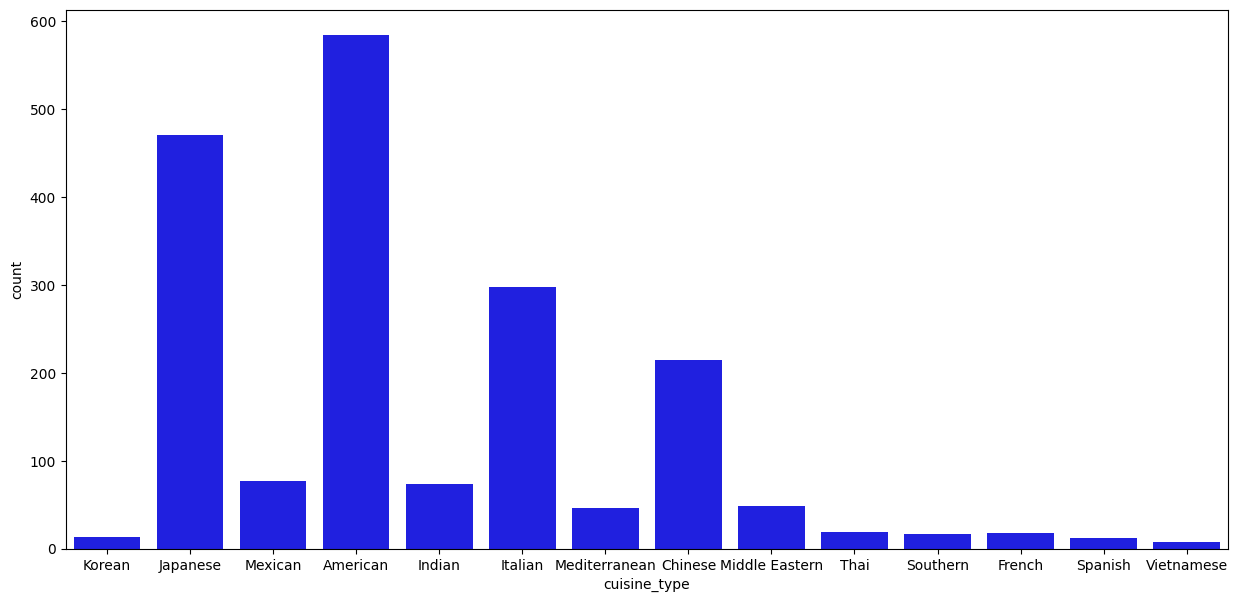

In [17]:
#CuisineType

plt.figure(figsize = (15,7))
sns.countplot(data = df, x = 'cuisine_type', color="blue")
plt.show()

- *The bar chart shows various cuisines. *

    - *Chinese has the highest with around 580 publications*
    - *Korean cuisine has the second at around 520.*
    - *Southern, French, Spanish, and Vietnamese cuisine seem to be having the lowest publications*

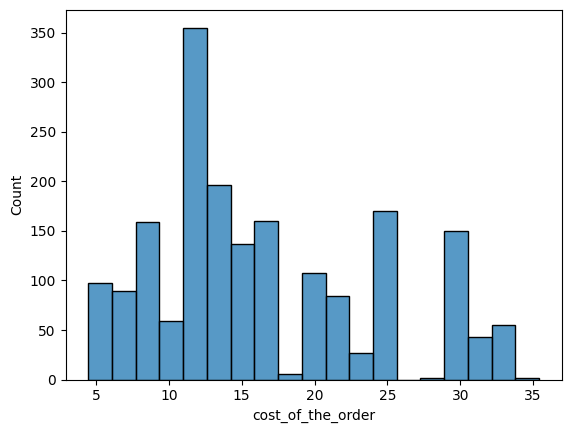

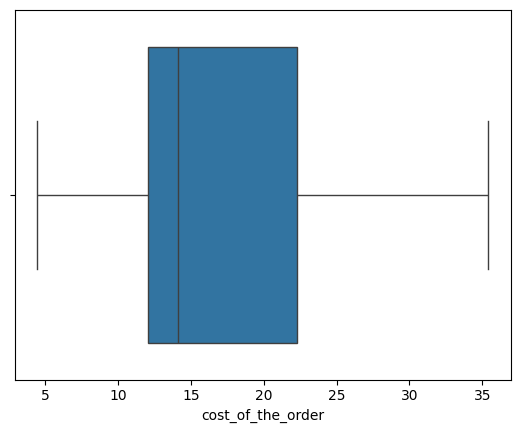

In [18]:
#Cost of the Order
sns.histplot(data=df,x='cost_of_the_order')
plt.show()
sns.boxplot(data=df,x='cost_of_the_order')
plt.show()

- *appears to be skewed to the right, meaning there are more orders towards the lower end of the cost spectrum.*
- *histogram tails off to the right, indicating some orders are more expensive than the others.*

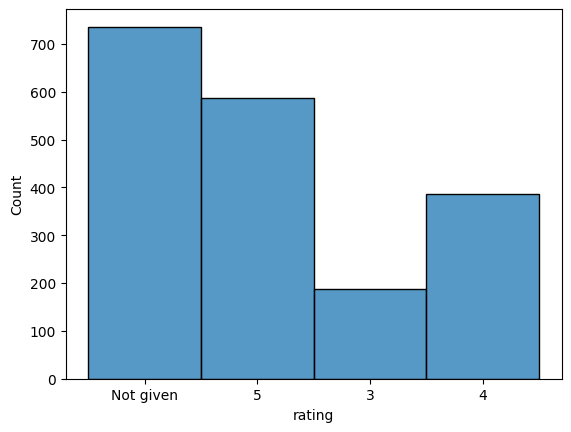

In [19]:
#Rating
sns.histplot(data=df,x='rating')
plt.show()

- Most of the orders were not rated*
- Least rated order got 3
- For the unrated orders we can assume that users might be less motivated to leave a rating for a successful delivery

<Axes: xlabel='day_of_the_week', ylabel='count'>

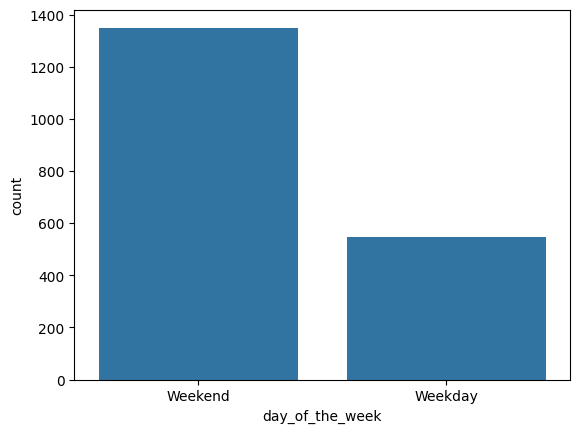

In [20]:
#Day of the week
sns.countplot(data = df, x = 'day_of_the_week')

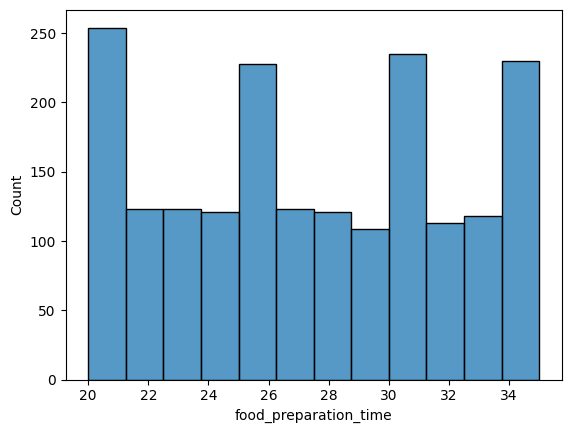

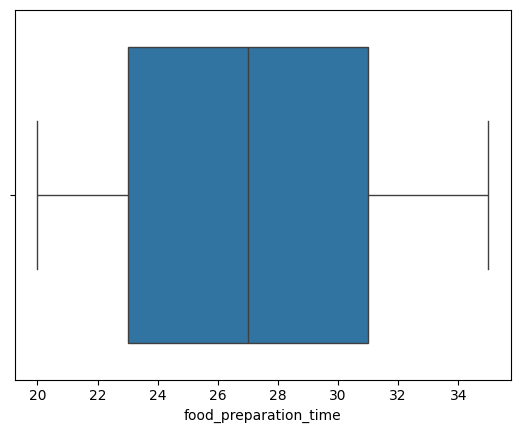

In [21]:
#Food preparation time
sns.histplot(data=df,x='food_preparation_time')
plt.show()
sns.boxplot(data=df,x='food_preparation_time')
plt.show()

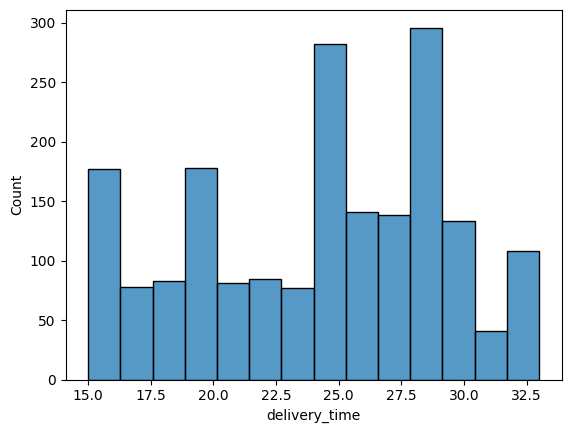

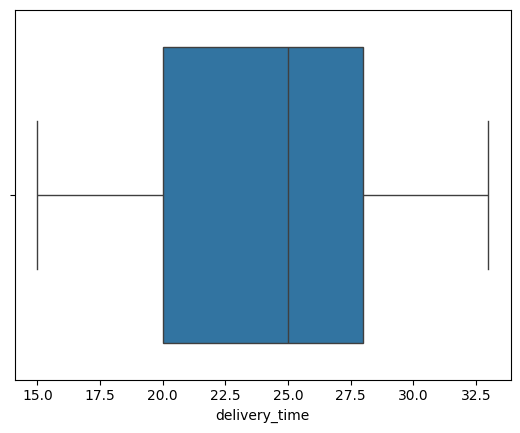

In [22]:
#Delivery Time
sns.histplot(data=df,x='delivery_time')
plt.show()
sns.boxplot(data=df,x='delivery_time')
plt.show()

### **Question 7**: Which are the top 5 restaurants in terms of the number of orders received? [1 mark]

In [23]:
# Write the code here

df['restaurant_name'].value_counts()

,count
restaurant_name,
Shake Shack,219
The Meatball Shop,132
Blue Ribbon Sushi,119
Blue Ribbon Fried Chicken,96
Parm,68
...,...
Sushi Choshi,1
Dos Caminos Soho,1
La Follia,1


#### Observations:

Shake Shack tops the list with 219 orders.

The Meatball Shop follows with 132 orders.

Blue Ribbon Sushi ranks third with 119 orders.

Blue Ribbon Fried Chicken is in fourth place with 96 orders.

Parm holds the fifth spot with 68 orders.

### **Question 8**: Which is the most popular cuisine on weekends? [1 mark]

In [24]:
# Write the code here

weekend = df[df['day_of_the_week'] == 'Weekend']
weekend['cuisine_type'].value_counts()

,count
cuisine_type,
American,415
Japanese,335
Italian,207
Chinese,163
Mexican,53
Indian,49
Mediterranean,32
Middle Eastern,32
Thai,15


#### Observations:
The popular cuisine during the weekend  is American with 415 orders

### **Question 9**: What percentage of the orders cost more than 20 dollars? [2 marks]

In [11]:
# Write the code here
orders_greater_than_20 = df[df['cost_of_the_order']>20]


percentage = (orders_greater_than_20.shape[0] / df.shape[0]) * 100

print('percentage  of orders above 20: ', percentage)

percentage  of orders above 20:  29.24130663856691


#### Observations: Percentage of orders above 10 dollars are about 29%


### **Question 10**: What is the mean order delivery time? [1 mark]

In [13]:
# Write the code here

mean_delivery_time = df['delivery_time'].mean()

print("The mean delivery time is:", mean_delivery_time)

The mean delivery time is: 24.161749209694417


#### Observations: The mean delivery time for this orders is 24 minutes


### **Question 11:** The company has decided to give 20% discount vouchers to the top 3 most frequent customers. Find the IDs of these customers and the number of orders they placed. [1 mark]

In [27]:
# Write the code here
df['customer_id'].value_counts().head(3)

,count
customer_id,
52832,13
47440,10
83287,9


#### Observations:
- *customer with id 52832 ordered 13 times*
- *customer with id 47440 ordered 10 times*
- *customer with id 83287 ordered 9 times*



### Multivariate Analysis

### **Question 12**: Perform a multivariate analysis to explore relationships between the important variables in the dataset. (It is a good idea to explore relations between numerical variables as well as relations between numerical and categorical variables) [10 marks]


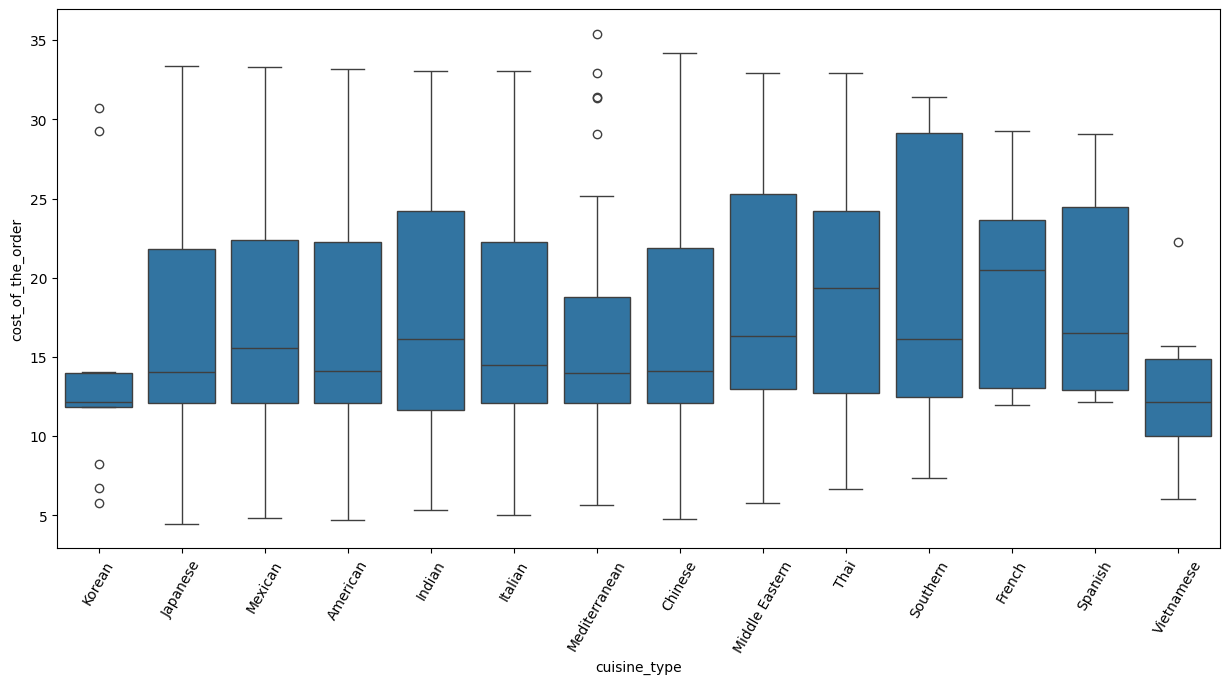

In [26]:
# Write the code here
plt.figure(figsize=(15,7))
sns.boxplot(x = "cuisine_type", y = "cost_of_the_order", data = df)
plt.xticks(rotation = 60)
plt.show()

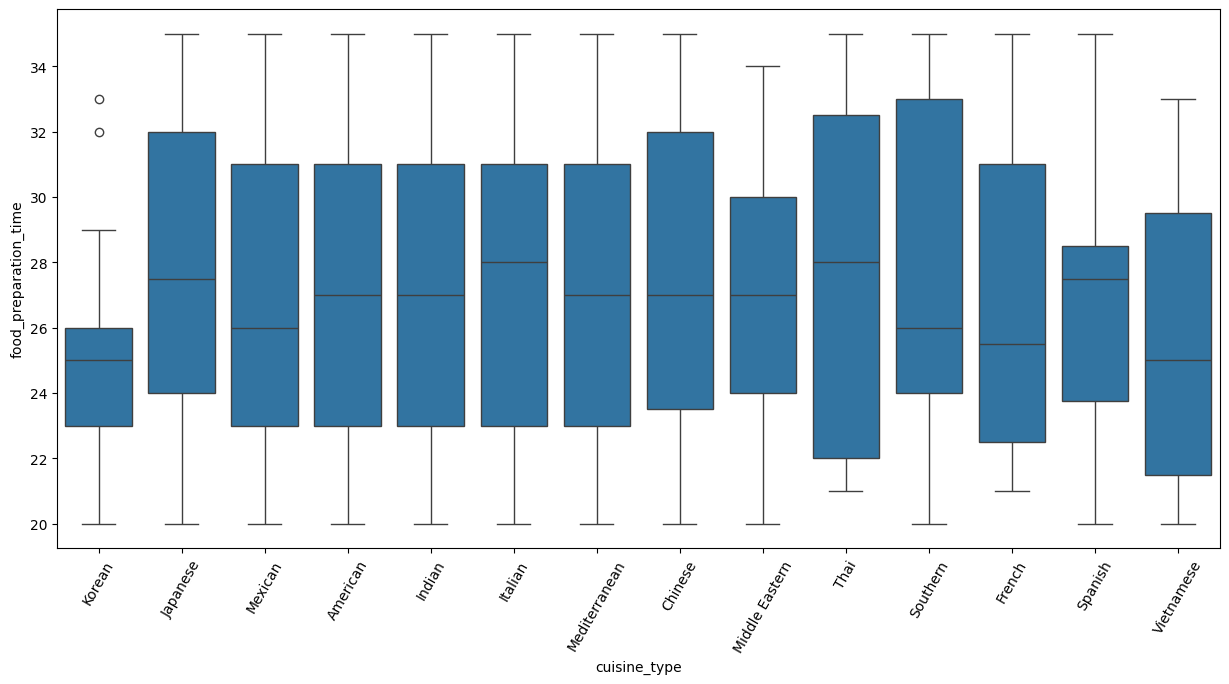

In [29]:
plt.figure(figsize=(15,7))
sns.boxplot(x = "cuisine_type",y="food_preparation_time", data = df)
plt.xticks(rotation = 60)
plt.show()

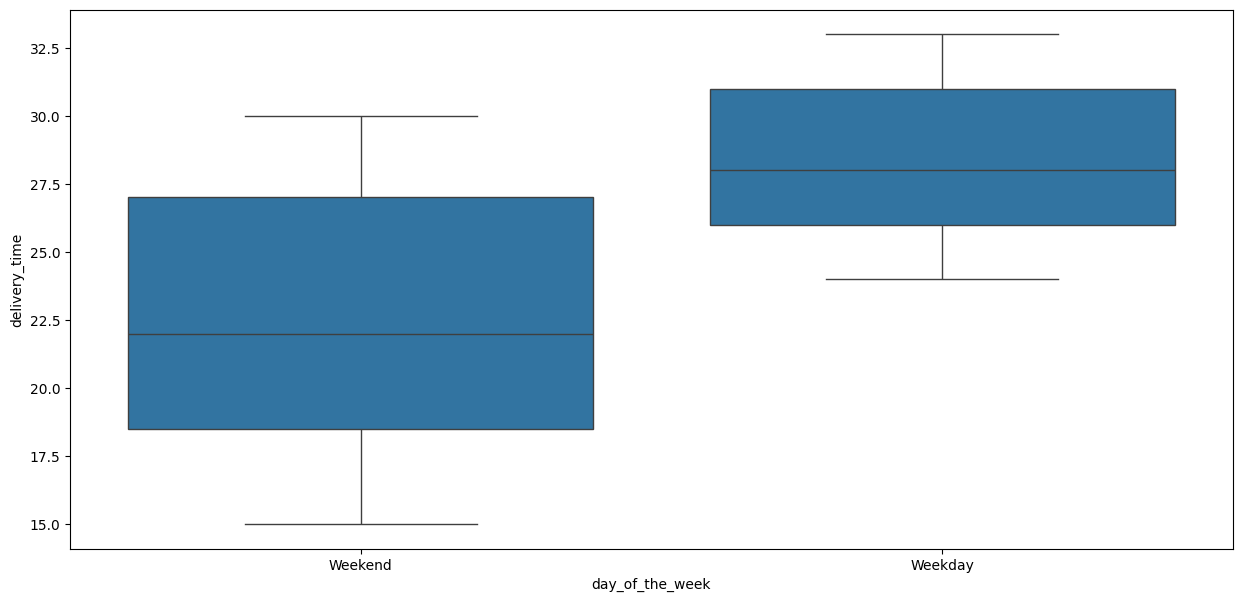

In [30]:
plt.figure(figsize=(15,7))
sns.boxplot(x = "day_of_the_week",y="delivery_time", data = df)
plt.show()

- *less spread in delivery times on weekdays*
- *greater spread in delivery times on weekends*
- *median delivery time on weekends seems to be higher*


### **Question 13:** The company wants to provide a promotional offer in the advertisement of the restaurants. The condition to get the offer is that the restaurants must have a rating count of more than 50 and the average rating should be greater than 4. Find the restaurants fulfilling the criteria to get the promotional offer. [3 marks]

In [16]:
# Write the code here

# Filter out orders with ratings
rated = df[df['rating'] != 'Not given'].copy()
rated['rating'] = rated['rating'].astype(int)

# Group by restaurant name and count ratings
rating_count = rated.groupby('restaurant_name')['rating'].count().reset_index()

# Filter restaurants with more than 50 ratings
rest_names = rating_count[rating_count['rating'] > 50]['restaurant_name']

# Calculate the mean rating for these restaurants
df_mean = rated[rated['restaurant_name'].isin(rest_names)]
mean_ratings = df_mean.groupby('restaurant_name')['rating'].mean().reset_index().sort_values(by='rating', ascending=False)

# result
mean_ratings.dropna().head()


,restaurant_name,rating
3,The Meatball Shop,4.511905
0,Blue Ribbon Fried Chicken,4.328125
2,Shake Shack,4.278195
1,Blue Ribbon Sushi,4.219178


#### Observations:

we have 4 restaurant that would likely be promoted
 - *The Meatball Shop with a rating of 4.5*
 - *Blue Ribbon Fried Chicken with a rating of 4.3*
 - *Shake Shack	 with a rating of 4.27*
 - *Blue Ribbon Sushi with a rating of 4.21*

### **Question 14:** The company charges the restaurant 25% on the orders having cost greater than 20 dollars and 15% on the orders having cost greater than 5 dollars. Find the net revenue generated by the company across all orders. [3 marks]

In [18]:
# Write the code here

def compute_revenue(cost):
    if cost > 20:
        return cost * 0.25
    elif cost > 5:
        return cost * 0.15
    return 0

df['Revenue'] = df['cost_of_the_order'].apply(compute_revenue)

print(df.head())

total_revenue = df['Revenue'].sum()
print("Total Revenue:", total_revenue)

   order_id  customer_id            restaurant_name cuisine_type  \
0   1477147       337525                    Hangawi       Korean   
1   1477685       358141  Blue Ribbon Sushi Izakaya     Japanese   
2   1477070        66393                Cafe Habana      Mexican   
3   1477334       106968  Blue Ribbon Fried Chicken     American   
4   1478249        76942           Dirty Bird to Go     American   

   cost_of_the_order day_of_the_week     rating  food_preparation_time  \
0              30.75         Weekend  Not given                     25   
1              12.08         Weekend  Not given                     25   
2              12.23         Weekday          5                     23   
3              29.20         Weekend          3                     25   
4              11.59         Weekday          4                     25   

   delivery_time  Revenue  
0             20   7.6875  
1             23   1.8120  
2             28   1.8345  
3             15   7.3000  
4     

#### Observations:
The net revenue is around 6166.3 dollars


### **Question 15:** The company wants to analyze the total time required to deliver the food. What percentage of orders take more than 60 minutes to get delivered from the time the order is placed? (The food has to be prepared and then delivered.) [2 marks]

In [20]:
# Write the code here
df['total_time'] = df['food_preparation_time'] + df['delivery_time']

percentage_long_delivery = (df['total_time'] > 60).mean() * 100

print("Percentage of orders exceeding 60 minutes:", percentage_long_delivery)

Percentage of orders exceeding 60 minutes: 10.537407797681771


#### Observations:10.54% of orders take more than 60 minutes to deliver.


### **Question 16:** The company wants to analyze the delivery time of the orders on weekdays and weekends. How does the mean delivery time vary during weekdays and weekends? [2 marks]

In [37]:
# Write the code here

weekday_delivery_time = round(df[df['day_of_the_week'] == 'Weekday']['delivery_time'].mean(), 2)
print(weekday_delivery_time)

weekend_delivery_time = round(df[df['day_of_the_week'] == 'Weekend']['delivery_time'].mean(), 2)
print(weekend_delivery_time)

28.34
22.47


#### Observations:

- *Faster delivery during weekends with.a mean of 22.47 while during the week day we have a mean of 28.34*

### Conclusion and Recommendations

### **Question 17:** What are your conclusions from the analysis? What recommendations would you like to share to help improve the business? (You can use cuisine type and feedback ratings to drive your business recommendations.) [6 marks]

<ipython-input-24-5d5ca9621882>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='rating', data=df, order=df['rating'].value_counts().index, palette='coolwarm')


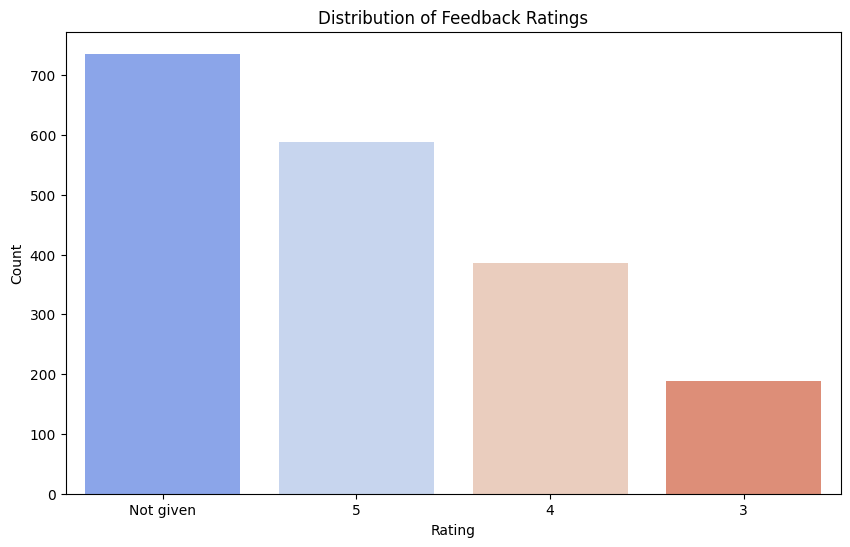

In [24]:
# Analyzing the distribution of ratings
plt.figure(figsize=(10, 6))
sns.countplot(x='rating', data=df, order=df['rating'].value_counts().index, palette='coolwarm')
plt.title('Distribution of Feedback Ratings')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.show()

In [21]:
#Weekend cuisine counts
weekend_cuisine_counts = df[df['day_of_the_week'] == 'Weekend']['cuisine_type'].value_counts()

print(weekend_cuisine_counts)

cuisine_type
American          415
Japanese          335
Italian           207
Chinese           163
Mexican            53
Indian             49
Mediterranean      32
Middle Eastern     32
Thai               15
French             13
Korean             11
Southern           11
Spanish            11
Vietnamese          4
Name: count, dtype: int64


In [39]:
Weekday = df[df['day_of_the_week'] == 'Weekday']
Weekday['cuisine_type'].value_counts()

,count
cuisine_type,
American,169
Japanese,135
Italian,91
Chinese,52
Mexican,24
Indian,24
Middle Eastern,17
Mediterranean,14
Southern,6


In [40]:
weekend = df[df['day_of_the_week'] == 'Weekend']
weekend['cuisine_type'].value_counts()

,count
cuisine_type,
American,415
Japanese,335
Italian,207
Chinese,163
Mexican,53
Indian,49
Mediterranean,32
Middle Eastern,32
Thai,15


### Conclusions:
- *Business Performance: The business appears to perform better during weekends in terms of both sales and delivery times.*
- *Popularity of American Cuisine: American cuisine is the most popular choice among customers on both weekends and weekdays.*
- *High Customer Preference for The Meatball Shop: The Meatball Shop is one of the most favored restaurants, consistently receiving high ratings and a large number of orders.*
- *Delivery Time Analysis: There is a noticeable difference in delivery times between weekdays and weekends, with faster deliveries observed on weekends.*
-*Order Preparation Time: The average food preparation time is relatively consistent, but there are instances where preparation times vary significantly.*
-*Customer Feedback and Ratings: The distribution of ratings suggests that many customers do not rate their orders, which could impact the overall feedback collection.*


### Recommendations:

 - *Improve Customer Experience: Identify the specific cuisines and restaurants with lower average ratings and investigate the reasons behind the low ratings. Implement strategies to address these issues, such as improving food quality, packaging, or delivery times.*
 - *Enhanced Weekend Offers: Since weekends show higher sales, consider introducing special weekend offers or combos to attract more customers and increase sales further.*
 - *Target Promotions: Utilize the popularity of highly-rated cuisines and restaurants to offer targeted promotions or discounts. For example, promote American and Japanese cuisines, which seem to be popular among customers.*
 - *Optimizing Delivery Times: Focus on improving delivery times during weekdays, as delivery times tend to be slower compared to weekends. This can be achieved by analyzing the current delivery process and identifying bottlenecks.*
 - *Implement Personalized Recommendations: Consider offering personalized recommendations based on customers' most frequently ordered items.*




---

In [27]:
!jupyter nbconvert --to html /content/drive/MyDrive/PGPAIML-Projects/Learner_Notebook_Full_Code.ipynb

[NbConvertApp] Converting notebook /content/drive/MyDrive/PGPAIML-Projects/Learner_Notebook_Full_Code.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 13 image(s).
[NbConvertApp] Writing 725472 bytes to /content/drive/MyDrive/PGPAIML-Projects/Learner_Notebook_Full_Code.html
